<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">

  <h1 style="color: #c25719; border-bottom: 2px solid #c25719; padding-bottom: 8px; margin-top: 0;">
    One Table of Nodules for LNDb and LIDC IDRI
  </h1>

  <p>
    Everything we model starts from a single table with one row per finding, whichever dataset it comes from. This notebook joins the LNDb table (notebook lndb_exploration) and the LIDC IDRI table (notebook lidc_exploration), checks it, and selects from it the <strong>study cohort</strong>: the nodules that the models learn from and are evaluated on.
  </p>
</div>

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))   # repository root, so that `import src` works
import warnings
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.spatial.distance import cdist
from src.mass_detect.scripts.cohort import select_cohort
from src.mass_detect.scripts.config import LIDC_NODULES_FILE, LNDB_NODULES_FILE, NODULE_TABLE
from src.mass_detect.scripts.schema import SCHEMA

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
COLORS = {"LNDb": "blue", "LIDC": "orange"}

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   The shared schema
  </h3>
  <p>
    Both datasets are described with the same columns. The ones that matter most for modelling are the position of the nodule in millimetres (<code>x_mm</code>, <code>y_mm</code>, <code>z_mm</code>), its size (<code>diameter_mm</code>), the mean rating (<code>mal_mean</code>) and the keys that protect us from leakage (<code>scan_id</code>, <code>patient_id</code>). We also keep scanner information (manufacturer, kernel, slice thickness), because the two datasets come from very different acquisition setups and these columns define the subgroups of the fairness analysis.
  </p>
  <p>
    A few conventions are worth knowing:
  </p>
  <ul style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;">The unit of analysis is the nodule. The readings of several radiologists are merged into one row, and <code>n_rated</code> keeps how many of them rated it, so that readings can be weighted later.</li>
    <li style="margin-bottom: 8px;">A rating of 0 in LNDb means that the field was not filled in, so it becomes a missing value and not a benign rating.</li>
    <li style="margin-bottom: 8px;"><code>mal_mean</code> is the mean of the ratings. The label is that mean rounded half up, and nodules rated around 3 are kept, because excluding the indeterminate ones makes the problem look easier than it is (notebook 00).</li>
  </ul>
</div>

In [2]:
# The schema lives in src/mass_detect/scripts/schema.py (together with equivalent_diameter)
print(Path.cwd().parent.joinpath("src", "mass_detect", "scripts", "schema.py").read_text())

"""The shared column schema of the nodule table and the equivalent diameter."""
import math
import numpy as np

SCHEMA = [
    "dataset",                # LNDb or LIDC
    "scan_id",                # unique CT id: LNDb-0001, or the series UID in LIDC
    "patient_id",             # grouping key for validation (in LNDb we assume one CT per patient)
    "nodule_uid",             # unique nodule id across both datasets
    "x_mm", "y_mm", "z_mm",   # nodule centre in world coordinates (mm), in each dataset's own CT frame
    "diameter_mm",            # diameter of the sphere with the same volume as the segmentation
    "volume_mm3",             # mean volume of the segmentation
    "volume_is_placeholder",  # LNDb: 3 mm sphere stored when radiologists only marked a centre
    "is_nodule",              # 1 nodule, 0 non nodule (LIDC only contains nodules of 3 mm or more)
    "mal_mean", "mal_min", "mal_max",  # malignancy ratings from 1 to 5, NaN when unrated
    "n_rated",                

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   Loading the two tables
  </h3>
  <p>
    The LNDb table is built in lndb_exploration and the LIDC IDRI table in lidc_exploration, where the six LIDC IDRI groups that stayed above four annotations were removed. Each notebook saves its table as a CSV; here we only join them.
  </p>
</div>

In [3]:
lndb = pd.read_csv(LNDB_NODULES_FILE)
lidc = pd.read_csv(LIDC_NODULES_FILE)
print("LNDb rows:", len(lndb), "| LIDC rows:", len(lidc))

LNDb rows: 1219 | LIDC rows: 2657


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   Joining the two tables
  </h3>
  <p>
    Because both tables follow the same schema, joining them is a plain concatenation. The checks make sure that the keys are unique, that the ratings are in range and that non nodules never carry a rating. The joined table is saved, because notebooks 04 to 06 read it.
  </p>
</div>

In [4]:
table = pd.concat([lndb, lidc], ignore_index=True)[SCHEMA]

assert table["nodule_uid"].is_unique
assert table["mal_mean"].dropna().between(1, 5).all()
assert (table.loc[table["is_nodule"] == 0, "n_rated"] == 0).all()
assert (table["n_rated"] <= table["n_readings"]).all()
table.to_csv(NODULE_TABLE, index=False)              # read by notebooks 04 to 06
print(f"saved {len(table)} rows -> {NODULE_TABLE.name}")

nodules = table[table["is_nodule"] == 1]
nodules.groupby("dataset").agg(
    nodules=("nodule_uid", "size"),
    patients=("patient_id", "nunique"),
    rated=("mal_mean", "count"),
    median_diameter_mm=("diameter_mm", "median"),
    mean_readers=("n_rated", "mean"),
).round(2)

saved 3876 rows -> nodule_table.csv


,nodules,patients,rated,median_diameter_mm,mean_readers
dataset,,,,,
LIDC,2657,874,2657,6.16,2.57
LNDb,768,212,765,4.94,1.34


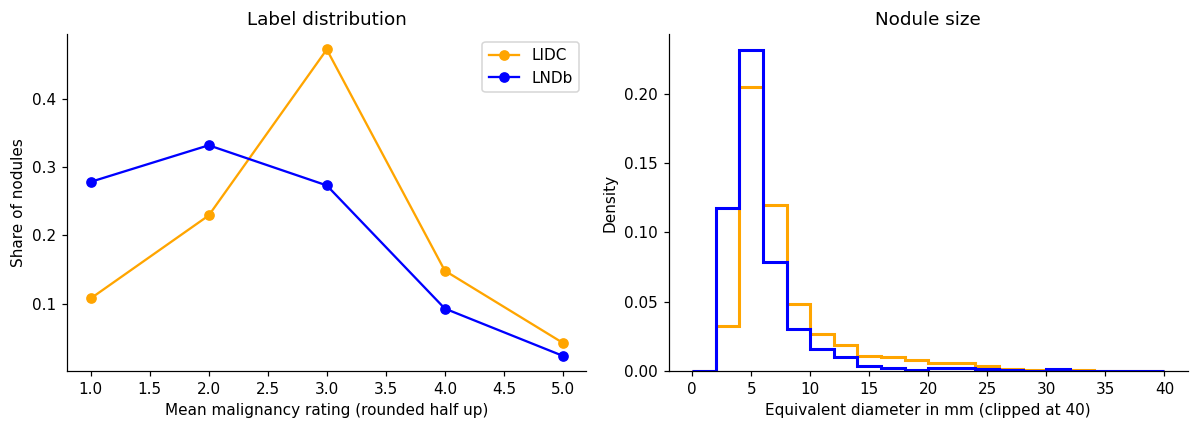

In [5]:
fig, (ax_label, ax_size) = plt.subplots(1, 2, figsize=(11, 4))
for name, group in nodules.groupby("dataset"):
    # Share of each rating, with the mean rounded half up (2.5 becomes 3)
    rounded = np.floor(group["mal_mean"].dropna() + 0.5)
    share = rounded.value_counts(normalize=True).reindex(range(1, 6), fill_value=0)
    ax_label.plot(share.index, share.values, marker="o", color=COLORS[name], label=name)

    # Distribution of the diameter, with the largest nodules grouped at 40 mm
    diameters = group["diameter_mm"].dropna().clip(upper=40)
    ax_size.hist(diameters, bins=np.arange(0, 41, 2), density=True, histtype="step",
                 linewidth=2, color=COLORS[name], label=name)

ax_label.set(xlabel="Mean malignancy rating (rounded half up)", ylabel="Share of nodules", title="Label distribution")
ax_size.set(xlabel="Equivalent diameter in mm (clipped at 40)", ylabel="Density", title="Nodule size")
ax_label.legend()
plt.tight_layout()
plt.show()

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
    The two datasets do not look alike. LNDb leans clearly towards benign ratings, while LIDC IDRI peaks at 3. Part of this is a side effect of averaging: LIDC IDRI nodules have on average about 2.6 ratings against 1.3 in LNDb, and a mean over several readers who disagree tends to land in the middle. LNDb also contains smaller nodules, which explains its smaller median diameter (4.9 against 6.2 mm). Both effects matter when the two datasets are pooled, so a rating of 3 should not be assumed to mean the same thing in both.
  </p>
</div>

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   The study cohort
  </h3>
  <p>
    A finding enters the study only if it passes every one of these rules, applied in this order:
  </p>
  <ol style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;"><strong>It is a nodule.</strong> Non nodules carry no malignancy rating and are not what the model is asked about.</li>
    <li style="margin-bottom: 8px;"><strong>It has a malignancy rating.</strong> A rating of 0 in LNDb means that the field was not filled in.</li>
    <li style="margin-bottom: 8px;"><strong>It has a radiologist mask, which means it measures 3 mm or more.</strong> The features are computed inside the region drawn by the radiologists. LIDC IDRI only describes nodules of 3 mm or more (Armato et al., 2011), while in LNDb the nodules under 3 mm were only marked with a centre (Pedrosa et al., 2019), so the same rule keeps the two populations comparable. Nodules this small are also of low clinical concern and do not need routine follow up (MacMahon et al., 2017).</li>
    <li style="margin-bottom: 8px;"><strong>Its LIDC IDRI group has at most four annotations.</strong> LIDC IDRI has four radiologists, so a larger group mixes more than one nodule. These groups were already removed in lidc_exploration, so this rule is a safeguard.</li>
    <li style="margin-bottom: 8px;"><strong>Its LIDC IDRI position was confirmed when the patch was cut.</strong> Notebook 04 computes the centre in two independent ways and keeps the nodules where both agree within 1 mm. Without that check the mask could fall next to the nodule instead of on it.</li>
  </ol>
  <p>
    The label is the mean of the radiologists' ratings rounded half up, so 2.5 becomes 3. We study two scales: the original 1 to 5, and a 1 to 3 scale derived from it (benign for ratings 1 and 2, indeterminate for 3, suspicious for 4 and 5), which follows the decision a clinician takes about a nodule. Deriving the 1 to 3 scale from the rounded rating keeps the two scales consistent with each other (notebook 00).
  </p>
</div>

In [6]:
# Inclusion rules and labels on both scales: src/mass_detect/scripts/cohort.py
cohort, funnel = select_cohort(table)
print(f"{len(cohort)} nodules from {cohort.patient_id.nunique()} patients")
funnel

3237 nodules from 1062 patients


dataset,LIDC,LNDb,total
all findings,2657,1219,3876
is a nodule,2657,768,3425
has a malignancy rating,2657,765,3422
has a radiologist mask (3 mm or more),2657,622,3279
at most four annotations (LIDC),2657,622,3279
position confirmed in its patch (LIDC),2615,622,3237


In [7]:
# Number of nodules in each class, on both scales
scale_5 = cohort.groupby("dataset")["rating"].value_counts().unstack()
scale_3 = cohort.groupby("dataset")["rating_3"].value_counts().unstack()
labels = pd.concat({"1 to 5": scale_5, "1 to 3": scale_3}, axis=1)
labels.loc["total"] = labels.sum()
labels

1 to 5                      1 to 3           
             1    2     3    4    5      1     2    3
dataset                                              
LIDC       286  603  1237  387  102    889  1237  489
LNDb       138  197   199   70   18    335   199   88
total      424  800  1436  457  120   1224  1436  577

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
    The rules leave <strong>3237 nodules from 1062 patients</strong>: 622 from LNDb and 2615 from LIDC IDRI. Most of what is lost are the 143 LNDb nodules under 3 mm, which have no mask; in LIDC IDRI, 42 nodules could not have their position confirmed.
  </p>
  <p>
    Pooling the two datasets brings the most suspicious class from 18 nodules in LNDb alone to 120, which makes it learnable. The two datasets still rate differently: 47% of the LIDC IDRI nodules are rated 3, against 32% in LNDb, and on the 1 to 3 scale 19% of the LIDC IDRI nodules are suspicious, against 14% in LNDb. This difference in rating habits is why notebook 06 compares several ways of combining the datasets.
  </p>
</div>

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   The training duplicates
  </h3>
  <p>
    Some LNDb findings of the same CT lie less than 3 mm apart. In the LNDb files each finding comes from merging the readings of several radiologists, and readings are merged only if they agree on the type. When one radiologist marked a structure as a nodule and another marked the same place as a non nodule, the same lesion appears twice. We check what these pairs are.
  </p>
</div>

In [8]:
# Pairs of LNDb findings in the same CT whose centres are less than 3 mm apart
pairs = []
lndb_findings = table[table["dataset"] == "LNDb"]
for scan, group in lndb_findings.groupby("scan_id"):
    centres = group[["x_mm", "y_mm", "z_mm"]].to_numpy()
    distance = cdist(centres, centres)
    np.fill_diagonal(distance, np.inf)          # a finding is not paired with itself
    for i, j in zip(*np.where(np.triu(distance < 3))):
        first, second = group.iloc[i], group.iloc[j]
        pairs.append({
            "a nodule and a non nodule": first["is_nodule"] != second["is_nodule"],
            "rows with a rating": int(pd.notna(first["mal_mean"])) + int(pd.notna(second["mal_mean"])),
        })

pairs = pd.DataFrame(pairs)
print("pairs closer than 3 mm in the same CT:", len(pairs))
pairs.value_counts().rename("pairs").to_frame()

pairs closer than 3 mm in the same CT: 59


,,pairs
a nodule and a non nodule,rows with a rating,
True,1,59


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
    All 59 pairs are a nodule and a non nodule, and in every pair only one row has a malignancy rating. The labelled nodules we train on therefore never appear twice, and the unrated twin rows are not used. Validation is also grouped by patient, so even a hidden duplicate would stay on one side of every split.
  </p>

  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   Limits to keep in mind
  </h3>
  <ol style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;">The datasets do not measure exactly the same thing. LIDC IDRI only contains nodules of 3 mm or more, read by up to four radiologists. LNDb also includes smaller nodules and non nodules, and most of its nodules were read by a single radiologist, so the label is noisier in LNDb.</li>
    <li style="margin-bottom: 8px;">The regrouped LIDC IDRI nodules rest on a heuristic. They are marked in 'reclustered', and a sensitivity analysis with and without them is planned. The groups that stayed above four annotations were removed.</li>
    <li style="margin-bottom: 8px;">Coordinates come from each dataset's own frame. They are only meaningful together with their own CT, which is all we need to cut patches.</li>
    <li style="margin-bottom: 8px;">Validation must group by 'patient_id'. Rows from the same patient share scanner and anatomy.</li>
    <li style="margin-bottom: 8px;">Scanners differ a lot. LNDb comes from one hospital and three Siemens models, while LIDC IDRI mixes many vendors. Both datasets are validated, so the effect of pooling them is measured in each one.</li>
  </ol>
</div>